In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
!gh --version

gh version 2.102.0 (2026-09-30)
https://github.com/cli/cli/releases/tag/v2.102.0


In [9]:
!gh auth login

78? Where do you use GitHub?  [Use arrows to move, type to filter]
> GitHub.com
  Other
7^C


In [10]:
!gh auth login --hostname github.com --git-protocol https --web

? Authenticate Git with your GitHub credentials? (Y/n) 7^C


In [11]:
!gh auth status

You are not logged into any GitHub hosts. To log in, run: gh auth login


In [12]:
from getpass import getpass
import os

github_token = getpass("Enter GitHub token: ")
os.environ["GH_TOKEN"] = github_token

Enter GitHub token: ··········


In [13]:
!echo "$GH_TOKEN" | gh auth login --hostname github.com --with-token

The value of the GH_TOKEN environment variable is being used for authentication.
To have GitHub CLI store credentials instead, first clear the value from the environment.


In [14]:
!gh auth status

github.com
  ✓ Logged in to github.com account deepanshurajpoot777-cpu (GH_TOKEN)
  - Active account: true
  - Git operations protocol: https
  - Token: ghp_************************************
  - Token scopes: 'admin:enterprise', 'admin:gpg_key', 'admin:org_hook', 'admin:public_key', 'admin:repo_hook', 'admin:ssh_signing_key', 'audit_log', 'codespace', 'copilot', 'delete:packages', 'delete_repo', 'gist', 'notifications', 'project', 'repo', 'user', 'workflow', 'write:discussion', 'write:network_configurations', 'write:packages'
  ! Missing required token scopes: 'read:org'
  - To request missing scopes, run: gh auth refresh -h github.com


In [15]:
!git push origin main

fatal: could not read Username for 'https://github.com': No such device or address


In [16]:
import os
from getpass import getpass

if not os.environ.get("GH_TOKEN"):
    os.environ["GH_TOKEN"] = getpass("Enter your GitHub token: ")

!git remote -v

origin	https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git (fetch)
origin	https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git (push)


In [17]:
import os
import getpass

token = os.environ.get("GH_TOKEN")

if not token:
    token = getpass.getpass("GitHub token enter karo: ")

!git -c "http.extraheader=AUTHORIZATION: basic $(echo -n 'x-access-token:'$token | base64 -w 0)" push origin main

Everything up-to-date


In [18]:
import torch
print("Cuda available",torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU:",torch.cuda.get_device_name(0))

Cuda available True
GPU: Tesla T4


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from  sklearn.model_selection import train_test_split
import torch.nn as nn
from  PIL import Image

In [32]:
from google.colab import files
uploaded=files.upload()

Saving real_fake.zip to real_fake (1).zip


In [26]:
import zipfile

zip_path="real_fake.zip"
extract_path="/content/real_fake_cnn"

with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)

print("Extraction Complete!")

Extraction Complete!


In [28]:
import os
print(os.listdir("/content/real_fake_cnn/Final Dataset"))

['Real', 'Fake', 'dataset.csv']


In [29]:
import os
dataset_path="/content/real_fake_cnn/Final Dataset"
for class_name in os.listdir(dataset_path):
  class_path=os.path.join(dataset_path,class_name)
  if os.path.isdir(class_path):
    print(class_name,":",len(os.listdir(class_path)))

Real : 5890
Fake : 7000


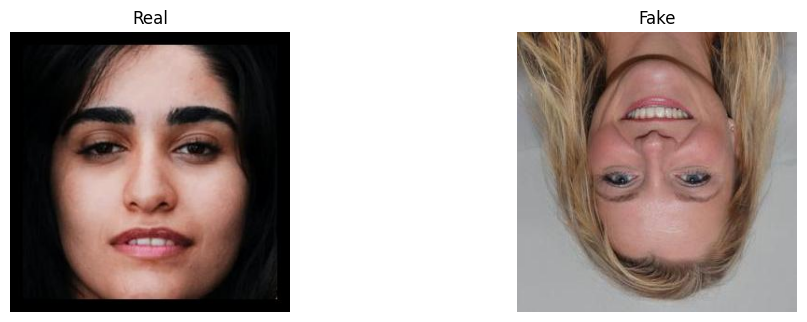

In [36]:
dataset_path="/content/real_fake_cnn/Final Dataset"
classes=os.listdir(dataset_path)
plt.figure(figsize=(12,8))

# Filter out files and only keep directories
class_dirs = [c for c in classes if os.path.isdir(os.path.join(dataset_path, c))]

for i, class_name in enumerate(class_dirs):
  class_path=os.path.join(dataset_path,class_name)
  image_name=os.listdir(class_path)[0]
  image_path=os.path.join(class_path,image_name)

  image=Image.open(image_path)

  plt.subplot(2,2,i+1)
  plt.imshow(image)
  plt.title(class_name)
  plt.axis("off")
plt.show()

In [37]:
from PIL import Image
import os

dataset_path="/content/real_fake_cnn/Final Dataset"

class_name="Real"
class_path=os.path.join(dataset_path,class_name)

image_name=os.listdir(class_path)[0]
image_path=os.path.join(class_path,image_name)

image=Image.open(image_path)

print("Image Size",image.size)
print("Image Mode",image.mode)

Image Size (330, 330)
Image Mode RGB


In [38]:
!git add .
!git commit -m "Add image preprocessing"

[main 4cbd705] Add image preprocessing
 2 files changed, 0 insertions(+), 0 deletions(-)
 create mode 100644 real_fake (1).zip
 create mode 100644 real_fake.zip


In [40]:
!git rm --cached "real_fake (1).zip"

rm 'real_fake (1).zip'


In [41]:
with open(".gitignore", "a") as f:
    f.write("\n# Dataset files\n*.zip\n")

In [42]:
!git add .gitignore
!git commit -m "Exclude dataset ZIP from Git"

[main 16cf88a] Exclude dataset ZIP from Git
 2 files changed, 3 insertions(+)
 create mode 100644 .gitignore
 delete mode 100644 real_fake (1).zip


In [43]:
!git -c "http.extraheader=AUTHORIZATION: basic $(echo -n 'x-access-token:'$GH_TOKEN | base64 -w 0)" push origin main

Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (6/6), 242.94 MiB | 10.93 MiB/s, done.
Total 6 (delta 0), reused 0 (delta 0), pack-reused 0
remote: error: Trace: d56f11230ad8ac1121d8ea31e6cad03917cc334ecfb7d393080a0fbf664badfc
remote: error: See https://gh.io/lfs for more information.
remote: error: File real_fake.zip is 244.19 MB; this exceeds GitHub's file size limit of 100.00 MB
remote: error: GH001: Large files detected. You may want to try Git Large File Storage - https://git-lfs.github.com.
To https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git
 ! [remote rejected] main -> main (pre-receive hook declined)
error: failed to push some refs to 'https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git'


In [44]:
!git filter-branch --force --index-filter \
'git rm --cached --ignore-unmatch "real_fake (1).zip" "real_fake.zip"' \
--prune-empty -- main

	 rewrites.  Hit Ctrl-C before proceeding to abort, then use an
	 alternative filtering tool such as 'git filter-repo'
	 (https://github.com/newren/git-filter-repo/) instead.  See the
	 filter-branch manual page for more details; to squelch this warning,
	 set FILTER_BRANCH_SQUELCH_WARNING=1.
Proceeding with filter-branch...

Rewrite 4cbd70512d0d494eede4aa4e634fe989f8c17ee6 (3/4) (0 seconds passed, remaining 0 predicted)    rm 'real_fake (1).zip'
rm 'real_fake.zip'
Rewrite 16cf88a843483a65b6024c2fa952d8a3bc4e7c07 (4/4) (0 seconds passed, remaining 0 predicted)    rm 'real_fake.zip'

Ref 'refs/heads/main' was rewritten


In [45]:
with open(".gitignore", "a") as f:
    f.write("\n*.zip\n")

In [46]:
!git rev-list --objects --all | grep -E 'real_fake.*\.zip'

9b720b29c02e4494573cc21faee29227bb441860 real_fake.zip


In [47]:
!git -c "http.extraheader=AUTHORIZATION: basic $(echo -n 'x-access-token:'$GH_TOKEN | base64 -w 0)" push origin main

To https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git
 ! [rejected]        main -> main (non-fast-forward)
error: failed to push some refs to 'https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git'
hint: Updates were rejected because the tip of your current branch is behind
hint: its remote counterpart. If you want to integrate the remote changes,
hint: use 'git pull' before pushing again.
hint: See the 'Note about fast-forwards' in 'git push --help' for details.


In [50]:
!git fetch origin


In [51]:
!git log --oneline --decorate -5

285c760 (HEAD -> main) Exclude dataset ZIP from Git
ec35626 Add initial test file
3e98a5b Initial commit


In [52]:
!git log origin/main --oneline -5

32a5531 (origin/main, origin/HEAD) Add initial test file
3dd3baa Initial commit


In [53]:
!git status

On branch main
Your branch and 'origin/main' have diverged,
and have 3 and 2 different commits each, respectively.
  (use "git pull" if you want to integrate the remote branch with yours)

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   .gitignore

no changes added to commit (use "git add" and/or "git commit -a")


In [54]:
!git log --oneline -5

285c760 (HEAD -> main) Exclude dataset ZIP from Git
ec35626 Add initial test file
3e98a5b Initial commit


In [55]:
!git rev-list --objects --all | grep -E 'real_fake.*\.zip'

9b720b29c02e4494573cc21faee29227bb441860 real_fake.zip


In [56]:
!git filter-repo --force --path real_fake.zip --path "real_fake (1).zip" --invert-paths

git: 'filter-repo' is not a git command. See 'git --help'.


In [57]:
!pip install git-filter-repo

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.3/76.3 kB 7.3 MB/s eta 0:00:00


In [58]:
!git filter-repo --force --path real_fake.zip --path "real_fake (1).zip" --invert-paths

NOTICE: Removing 'origin' remote; see 'Why is my origin removed?'
        in the manual if you want to push back there.
        (was https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git)
Parsed 7 commits
New history written in 0.08 seconds; now repacking/cleaning...
Repacking your repo and cleaning out old unneeded objects
HEAD is now at 285c760 Exclude dataset ZIP from Git
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (9/9), done.
Total 9 (delta 0), reused 4 (delta 0), pack-reused 0
Completely finished after 0.23 seconds.


In [59]:
!git rev-list --objects --all | grep -E 'real_fake.*\.zip'

In [60]:
!git remote add origin https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git

In [61]:
!git remote -v

origin	https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git (fetch)
origin	https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git (push)


In [62]:
!git rev-list --objects --all | grep -E 'real_fake.*\.zip'

In [63]:
!git fetch origin
!git log --oneline --decorate -5
!git log origin/main --oneline -5

remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (4/4), done.
remote: Total 6 (delta 0), reused 3 (delta 0), pack-reused 0 (from 0)
Unpacking objects: 100% (6/6), 1.16 KiB | 1.16 MiB/s, done.
From https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn
 * [new branch]      main       -> origin/main
285c760 (HEAD -> main) Exclude dataset ZIP from Git
ec35626 Add initial test file
3e98a5b Initial commit
32a5531 (origin/main) Add initial test file
3dd3baa Initial commit


In [64]:
!git status

On branch main
nothing to commit, working tree clean


In [65]:
!git -c "http.extraheader=AUTHORIZATION: basic $(echo -n 'x-access-token:'$GH_TOKEN | base64 -w 0)" push --force-with-lease origin main

Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (9/9), 894 bytes | 894.00 KiB/s, done.
Total 9 (delta 0), reused 9 (delta 0), pack-reused 0
To https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git
 + 32a5531...285c760 main -> main (forced update)


In [66]:
%cd /content/deepfake-image-detection-cnn
!ls -la

/content/deepfake-image-detection-cnn
total 250072
drwxr-xr-x 3 root root      4096 Oct 17 07:39  .
drwxr-xr-x 1 root root      4096 Oct 17 06:58  ..
drwxr-xr-x 9 root root      4096 Oct 17 07:42  .git
-rw-r--r-- 1 root root        23 Oct 17 07:39  .gitignore
-rw-r--r-- 1 root root        30 Oct 17 06:37  README.md
-rw-r--r-- 1 root root 256046723 Oct 17 07:22 'real_fake (1).zip'
-rw-r--r-- 1 root root        52 Oct 17 06:37  test.py


In [67]:
import os

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", ".cache"]]

    for file in files:
        if file.endswith(".py") and file not in ["test.py"]:
            print(os.path.join(root, file))

/content/drive/Othercomputers/My Laptop/Desktop/New folder/python.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/dsa.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/practice.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/list.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/Numpy_practice.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/matplotlib_practice.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/python-quiz-game.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/Movie-Recommender-project.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/ATM Managment System.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/Expense Tracker.py
/content/drive/Othercomputers/My Laptop/Desktop/New folder/pandas_practice.py


In [68]:
import os

for root, dirs, files in os.walk("/content/drive"):
    dirs[:] = [d for d in dirs if d not in [".git", ".cache"]]

    for file in files:
        if file.endswith(".ipynb"):
            print(os.path.join(root, file))

/content/drive/MyDrive/Colab Notebooks/deepfake_detection.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled0.ipynb
/content/drive/MyDrive/Colab Notebooks/lec1.ipynb
/content/drive/MyDrive/Colab Notebooks/Auto Grade.ipynb
/content/drive/MyDrive/Colab Notebooks/Training.pipeline.ipynb
/content/drive/MyDrive/Colab Notebooks/Untitled1.ipynb
/content/drive/MyDrive/Colab Notebooks/NN Module.ipynb
/content/drive/MyDrive/Colab Notebooks/NN module2.ipynb
/content/drive/MyDrive/Colab Notebooks/dataset-and-dataloder-demo.ipynb
/content/drive/MyDrive/Colab Notebooks/ANN-fashion-mnist-pytorch.ipynb
/content/drive/MyDrive/Colab Notebooks/ann-fashion-mnist-pytorch-gpu-optimized.ipynb
/content/drive/MyDrive/Colab Notebooks/cnn-fashion-mnist-pytorch-gpu-optimized.ipynb
/content/drive/MyDrive/Colab Notebooks/transfer-learning-fashion-mnist-pytorch-gpu.ipynb
/content/drive/MyDrive/Colab Notebooks/pytorch-rnn-baesd-QA-system.ipynb
/content/drive/MyDrive/Colab Notebooks/Dataset Dataloader.ipynb
/conten

In [69]:
import json

notebook_path = "/content/drive/MyDrive/Colab Notebooks/deepfake_detection.ipynb"

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        if source.strip():
            print(f"\n--- Code Cell {i} ---\n")
            print(source[:500])


--- Code Cell 0 ---

from google.colab import drive
drive.mount('/content/drive')

--- Code Cell 1 ---

!git clone https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git

--- Code Cell 2 ---

%cd /content/deepfake-image-detection-cnn

--- Code Cell 3 ---

!git config --global user.name "deepanshurajpoot777-cpu"
!git config --global user.email "deepanshurajpoot777@gmail.com"

--- Code Cell 4 ---

!git config --global user.name
!git config --global user.email

--- Code Cell 5 ---

%%writefile test.py

print("Deepfake Image Detection Project Started!")

--- Code Cell 7 ---

!git add test.py
!git commit -m "Add initial test file"

--- Code Cell 8 ---

!gh --version

--- Code Cell 9 ---

!gh auth login

--- Code Cell 10 ---

!gh auth login --hostname github.com --git-protocol https --web

--- Code Cell 11 ---

!gh auth status

--- Code Cell 14 ---

from getpass import getpass
import os

github_token = getpass("Enter GitHub token: ")
os.environ["GH_TOKEN"] = github_toke

In [70]:
import shutil

source = "/content/drive/MyDrive/Colab Notebooks/deepfake_detection.ipynb"
destination = "/content/deepfake-image-detection-cnn/deepfake_detection.ipynb"

shutil.copy2(source, destination)

print("Notebook copied successfully!")

Notebook copied successfully!


In [71]:
%cd /content/deepfake-image-detection-cnn

!git add deepfake_detection.ipynb
!git commit -m "Add deepfake detection notebook"

!git -c "http.extraheader=AUTHORIZATION: basic $(echo -n 'x-access-token:'$GH_TOKEN | base64 -w 0)" push origin main

/content/deepfake-image-detection-cnn
[main d8fb9a9] Add deepfake detection notebook
 1 file changed, 1 insertion(+)
 create mode 100644 deepfake_detection.ipynb
Enumerating objects: 4, done.
Counting objects: 100% (4/4), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 210.47 KiB | 13.15 MiB/s, done.
Total 3 (delta 0), reused 0 (delta 0), pack-reused 0
To https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git
   285c760..d8fb9a9  main -> main


ConvertImage in to tensor

In [72]:
import torch
from torchvision import transforms
from PIL import ImageChops
import os

dataset_path="/content/real_fake_cnn/Final Dataset"
class_name="Real"
class_path=os.path.join(dataset_path,class_name)

image_name=os.listdir(class_path)[0]
image_path=os.path.join(class_path,image_name)

image=Image.open(image_path)

transform=transforms.ToTensor()

image_tensor=transform(image)

print("Original image size:",image.size)
print("Tensor shape",image_tensor.shape)
print("Tensor Dats type",image_tensor.dtype)

Original image size: (330, 330)
Tensor shape torch.Size([3, 330, 330])
Tensor Dats type torch.float32


In [75]:
from torchvision import datasets,transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])
dataset=datasets.ImageFolder(
    root="/content/real_fake_cnn/Final Dataset",
    transform=transform

)
print("Total Image",len(dataset))
print("classes:",dataset.classes)
print("class to index:",dataset.class_to_idx)


Total Image 12890
classes: ['Fake', 'Real']
class to index: {'Fake': 0, 'Real': 1}


In [77]:
image,label=dataset[0]

print("Image Shape",image.shape)
print("Labels",label)
print("Class",dataset.classes[label])

Image Shape torch.Size([3, 224, 224])
Labels 0
Class Fake


In [80]:
from torch.utils.data import DataLoader

train_loader=DataLoader(
    dataset,
    batch_size=32,
    shuffle=True

)
print("Number of Batches",len(train_loader))

Number of Batches 403


In [82]:
image,labels =next(iter(train_loader))

print("Image Shape",image.shape)
print("label Shape",labels.shape)
print("Labels",labels)

Image Shape torch.Size([32, 3, 224, 224])
label Shape torch.Size([32])
Labels tensor([0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0,
        1, 0, 0, 1, 0, 1, 1, 1])


In [88]:
from torchvision import datasets, transforms

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

train_dataset=datasets.ImageFolder(
    "/content/real_fake_cnn/Final Dataset",
    transform=train_transform
)
test_dataset=datasets.ImageFolder(
    "/content/real_fake_cnn/Final Dataset",
    transform=test_transform
)

print("training Images:",len(train_dataset))
print("testing Images",len(test_dataset))

print("train Classes",train_dataset.classes)
print("test classes:",test_dataset.class_to_idx)

training Images: 12890
testing Images 12890
train Classes ['Fake', 'Real']
test classes: {'Fake': 0, 'Real': 1}


In [97]:
from torch.utils.data import random_split
import torch

total_size = len(dataset)

train_size = int(0.85 * total_size)
val_size = int(0.10 * total_size)
test_size = total_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("Total:", len(train_dataset) + len(val_dataset) + len(test_dataset))


Train: 10956
Validation: 1289
Test: 645
Total: 12890


In [98]:
import os

dataset_path = "/content/real_fake_cnn/Final Dataset"

print(os.listdir(dataset_path))

['Real', 'Fake', 'dataset.csv']


In [92]:
import shutil

source = "/content/drive/MyDrive/Colab Notebooks/deepfake_detection.ipynb"
destination = "/content/deepfake-image-detection-cnn/deepfake_detection.ipynb"

shutil.copy2(source, destination)

print("Notebook copied successfully!")

Notebook copied successfully!


In [93]:
%cd /content/deepfake-image-detection-cnn

!git add deepfake_detection.ipynb
!git commit -m "Add deepfake detection notebook"

!git -c "http.extraheader=AUTHORIZATION: basic $(echo -n 'x-access-token:'$GH_TOKEN | base64 -w 0)" push origin main

/content/deepfake-image-detection-cnn
[main 64772f7] Add deepfake detection notebook
 1 file changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 5, done.
Counting objects: 100% (5/5), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (3/3), 2.20 KiB | 450.00 KiB/s, done.
Total 3 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/deepanshurajpoot777-cpu/deepfake-image-detection-cnn.git
   d8fb9a9..64772f7  main -> main
